# Cast Your Bet: predicting movie ratings from year and genre

Hands-on lab for Lectures 1–6 of *Learning From Data*.

You will build a simple model that predicts the average MovieLens rating of a movie from its release year and genres. Before writing any code, guess the ratings of the four movies below. At the end of the notebook your guesses are compared with the model's predictions.


<table>
<tr><td>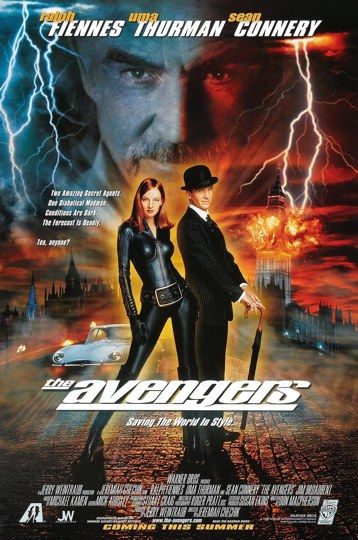</td><td>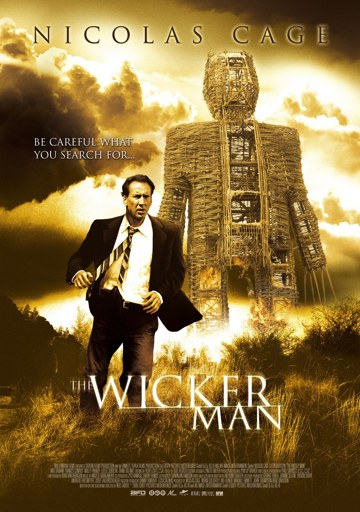</td><td>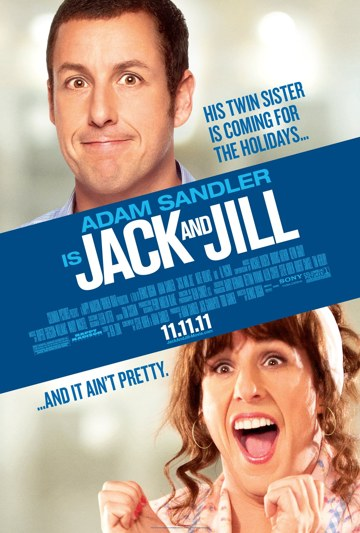</td><td>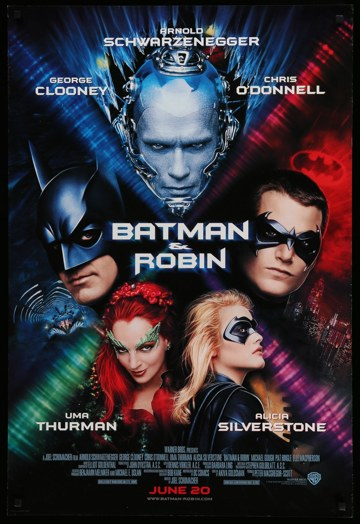</td></tr>
<tr><td>1. The Avengers (1998)<br><small>Ralph Fiennes, Uma Thurman, Sean Connery</small></td><td>2. The Wicker Man (2006)<br><small>Nicolas Cage, Ellen Burstyn</small></td><td>3. Jack and Jill (2011)<br><small>Adam Sandler, Katie Holmes, Al Pacino</small></td><td>4. Batman &amp; Robin (1997)<br><small>George Clooney, Uma Thurman, Arnold Schwarzenegger</small></td></tr>
</table>


### Your guesses

Guess each movie's average MovieLens rating on a 1–10 scale (the 5-star average multiplied by 2), in the order shown above. Don't look the scores up. If you have seen a movie or already know how it was received, set its entry in `seen_before` to `True`; it will then be left out of the comparison with the model.

Run the cell once and don't change your guesses afterwards. You can also leave them as `None`.

What influenced your guesses most: the actors, the poster, the genre or the title? One sentence.

**Answer:** My guesses were mostly influenced by the actors and the movie genres, giving higher scores to the ones starring actors I knew or more interesting genres, like action.


In [1]:
# Your guesses, in poster order.
if globals().get('challenge_revealed',False):
    print('The scores have already been shown. Keep your original guesses.')
else:
    human_guesses = [6.8, 7.5, 5.4, 7.3]  # Replace each None with your guess, in poster order.
    seen_before = [False, False, False, False]  # True = seen it or know its reputation.
    assert len(human_guesses)==4 and len(seen_before)==4
    assert all(g is None or (isinstance(g,(int,float)) and not isinstance(g,bool) and 1<=g<=10)
               for g in human_guesses), 'Each guess must be None or a number from 1 to 10.'
    assert all(isinstance(s,bool) for s in seen_before)
    print('Guesses recorded.')

Guesses recorded.


### How to use this notebook

Run the cells in order, in Colab or Jupyter. You only edit the lines marked `# TODO` (replace `None` with an expression) and the answer lines in the text cells. Each task cell runs a few checks and prints whether they passed. Don't rename the functions or change their arguments.

If you run it locally and an import fails, run `%pip install numpy pandas matplotlib scipy scikit-learn` in a new cell.


In [2]:
#@title Setup (run as is)
import base64, gzip, io, hashlib, itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from scipy.optimize import linprog

SEED = 17
rng = np.random.default_rng(SEED)
BLUE, ORANGE, DARK, GREY = 'tab:blue', 'tab:orange', '0.25', '0.55'
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})

def note(text, ok=False):
    print(text)

def bias(X):
    return np.column_stack([np.ones(len(X)), X])

def predict(X, w):
    return np.where(bias(X) @ w >= 0, 1, -1)

def line_map(ax, X, y, w, title):
    pad = .35
    gx = np.linspace(X[:, 0].min()-pad, X[:, 0].max()+pad, 150)
    gy = np.linspace(X[:, 1].min()-pad, X[:, 1].max()+pad, 150)
    xx, yy = np.meshgrid(gx, gy)
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    zz = predict(grid, w).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-2, 0, 2], colors=[BLUE, ORANGE], alpha=.12)
    if zz.min() != zz.max():
        ax.contour(xx, yy, zz, levels=[0], colors=[DARK], linewidths=1.2)
    jitter = np.random.default_rng(8).normal(0, .045, X.shape)
    for cls, color, label in [(-1, BLUE, 'score < 7'), (1, ORANGE, 'score ≥ 7')]:
        sel = y == cls
        ax.scatter(*(X[sel]+jitter[sel]).T, s=14, c=color, alpha=.35, label=label)
    ax.set(title=title)

print('Setup done.')

Setup done.


## Part 1: The data and the learning problem

Lectures 1 and 4. Task 1.


We use MovieLens latest-small (GroupLens, September 2018): 100,836 ratings of 9,742 movies by 610 users. The table loaded below has one row per movie, with its release year, genres, number of ratings and mean rating.

The target score is twice the mean rating, so it lies between 1 and 10. We use it in two ways:

- regression: predict the score itself;
- classification: $y=+1$ if the score is at least 7 (a "watchlist" movie), otherwise $y=-1$.

The input has six features: the release year, scaled as `(year - 1980) / 40`, and five 0/1 genre flags (Drama, Comedy, Action, Horror, Romance). A movie can have several flags.

We keep movies with at least 10 ratings and split them 60/20/20 into training, validation and test sets. The four poster movies are taken out before the split. Title, cast, number of ratings and the mean rating itself are not used as inputs.


Main movies: 2,267 | Train: 1,359 | Validation: 454 | Locked test: 454
The four poster movies are kept aside until the end.


,year_scaled,Drama,Comedy,Action,Horror,Romance,audience_score
0,0.300,0.0,1.0,0.0,0.0,1.0,7.785714
1,0.550,1.0,0.0,0.0,0.0,0.0,7.250000
2,0.475,1.0,0.0,0.0,0.0,0.0,7.423077
3,0.300,0.0,1.0,0.0,0.0,0.0,7.473684


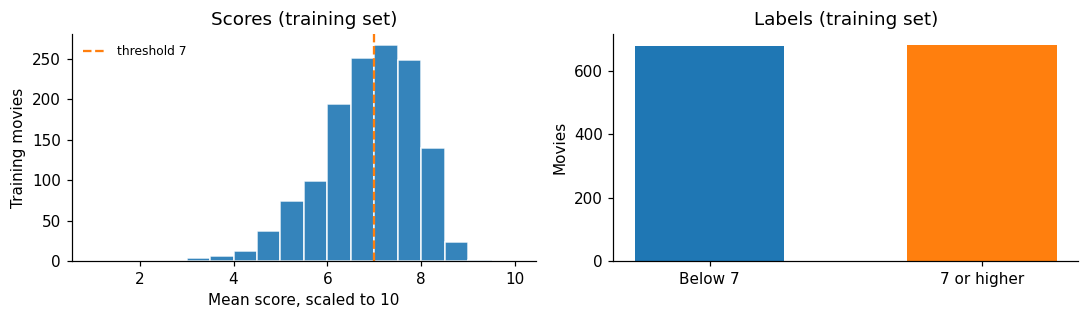

In [3]:
#@title Load the data (run as is)
DATA_B64 = "..."
raw_bytes=gzip.decompress(base64.b64decode(DATA_B64))
assert hashlib.sha256(raw_bytes).hexdigest() == 'a57a34f7c6c58180801089677bd9745f2b9712a554c3df3aa0770da6c6c78917'
films=pd.read_csv(io.BytesIO(raw_bytes))
CHALLENGE_IDS=[2153,47810,90890,1562]  # same order as the poster cards
challenge=films.set_index('movieId').loc[CHALLENGE_IDS].reset_index()
main=films.loc[~films.movieId.isin(CHALLENGE_IDS)].reset_index(drop=True)
assert (main['count']>=10).all() and not main.movieId.duplicated().any()
assert not set(main.movieId)&set(CHALLENGE_IDS)

def prepare_features(frame):
    genres=frame['genres'].str.split('|')
    return np.column_stack([
        (frame['year'].to_numpy()-1980)/40,
        *[genres.apply(lambda values:g in values).to_numpy(dtype=float)
          for g in ['Drama','Comedy','Action','Horror','Romance']]
    ]).astype(float)

FEATURES=['year_scaled','Drama','Comedy','Action','Horror','Romance']
X6=prepare_features(main)
scores=main['score10'].to_numpy(dtype=float)
y_all=np.where(scores>=7,1,-1)
ids=np.arange(len(main))
train_val_idx,test_idx=train_test_split(ids,test_size=.20,random_state=SEED,stratify=y_all)
train_idx,val_idx=train_test_split(train_val_idx,test_size=.25,random_state=SEED+1,
                                 stratify=y_all[train_val_idx])
X_train,y_train,score_train=X6[train_idx],y_all[train_idx],scores[train_idx]
X_val,y_val,score_val=X6[val_idx],y_all[val_idx],scores[val_idx]
locked_test={'X':X6[test_idx],'y':y_all[test_idx],'score':scores[test_idx],
             'title':main.loc[test_idx,'title'].to_numpy()}
print(f'Main movies: {len(main):,} | Train: {len(train_idx):,} | Validation: {len(val_idx):,} | Locked test: {len(test_idx):,}')
print('The four poster movies are kept aside until the end.')
display(pd.DataFrame(X_train[:4],columns=FEATURES).assign(audience_score=score_train[:4]))
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].hist(score_train,bins=np.arange(1,10.5,.5),color=BLUE,alpha=.9,edgecolor='white')
axes[0].axvline(7,color=ORANGE,ls='--',label='threshold 7')
axes[0].set(xlabel='Mean score, scaled to 10',ylabel='Training movies',title='Scores (training set)')
axes[0].legend(frameon=False,fontsize=8)
axes[1].bar(['Below 7','7 or higher'],[np.sum(y_train==-1),np.sum(y_train==1)],color=[BLUE,ORANGE],width=.55)
axes[1].set(title='Labels (training set)',ylabel='Movies')
plt.tight_layout();plt.show()

### Task 1: The learning problem

Answer each question in one sentence.

1. What are the input $x$, the regression target and the classification target here?

   **Answer:** The input $x$ is the six-dimensional vector containing the scaled release year and five genre indicators; the regression target is the movie's average rating on a 1–10 scale, and the classification target is +1 if that rating is at least 7 and -1 otherwise.

2. Why is a target distribution $P(y\mid x)$ a better description of movie scores than a deterministic target function $f(x)$?

   **Answer:** Because movies with the same year and genres can receive different ratings due to factors such as acting, directing, storytelling, and individual audience preferences, so the target is inherently uncertain given the available inputs.

3. In this lab, what are the hypothesis set $\mathcal H$, the learning algorithm $\mathcal A$ and the final hypothesis $g$?

   **Answer:** The hypothesis set $\mathcal H$ is the collection of candidate models considered, the learning algorithm $\mathcal A$ is the procedure used to select and fit a model from the training data, and $g$ is the final learned hypothesis.

4. Why is this supervised learning? What feedback would unsupervised learning and reinforcement learning work with instead?

   **Answer:** This is supervised learning because each movie's input features are accompanied by an observed rating that provides the target output; unsupervised learning instead works with unlabeled data, while reinforcement learning uses rewards or penalties resulting from actions.

5. Why can't the observed mean rating be used as an input feature, even when we only predict the ±1 label?

   **Answer:** Because the mean rating is the target we are trying to predict, including it as an input would cause target leakage and allow the model to access the answer instead of learning to predict it.


## Part 2: A watchlist classifier

Lectures 1, 3 and 4. Tasks 2–3.


### Task 2: Error measures

Complete the three functions below. Each one returns a single number.

| Function | Returns |
|:--|:--|
| `binary_error(y, pred)` | fraction of labels that differ (`np.mean` of a comparison) |
| `squared_error(y, score)` | mean squared difference |
| `watch_cost(y, pred)` | `(4 * fp + fn) / len(y)` |

A false positive recommends a movie with a score below 7; a false negative misses a movie with a score of 7 or more. Here a bad recommendation costs four times as much as a missed one. For regression we also report RMSE, the square root of the mean squared error, measured in rating points.

Would someone who enjoys discovering little-known movies choose the same costs? One sentence.

**Answer:** No, because someone who enjoys discovering lesser-known movies might consider missing a good movie more costly than receiving a disappointing recommendation, and therefore assign a higher cost to false negatives.

In [4]:
def binary_error(y, pred):
    value = np.mean(y != pred)  # TODO T2a: mean of the label mismatch indicator
    return value

def squared_error(y, score):
    value = np.mean((y - score) ** 2)  # TODO T2b: mean squared difference
    return value

def watch_cost(y, pred):
    fp = np.sum((y == -1) & (pred == 1))
    fn = np.sum((y == 1) & (pred == -1))
    value = (4 * fp + fn) / len(y)  # TODO T2c: weighted error count divided by len(y)
    return value

a = np.array([1, 1, -1, -1]); b = np.array([1, -1, 1, -1])
losses_ready = all(v is not None for v in [binary_error(a,b), squared_error(a,b), watch_cost(a,b)])
if losses_ready:
    assert np.isclose(binary_error(a,b), .5), 'Check the fraction of wrong labels.'
    assert np.isclose(squared_error(a,b), 2), 'Square each difference before averaging.'
    assert np.isclose(watch_cost(a,b), 1.25), 'Check the weighted count: a false recommendation costs 4.'
    assert np.isclose(watch_cost(np.array([-1]),np.array([1])),4), 'False recommendation costs 4.'
    assert np.isclose(watch_cost(np.array([1]),np.array([-1])),1), 'Skipping a highly rated film costs 1.'
    note('Task 2: all checks passed.')
else:
    note('Fill in T2a–T2c and run the cell again.')

Task 2: all checks passed.


### Task 3: Perceptron and Pocket

The model is $h(x)=\operatorname{sign}(w^\top x)$, with $x_0=1$ for the bias.

- T3a: compute the scores of all rows at once. `Xb` has shape `(N, d+1)` and `w` has shape `(d+1,)`.
- T3b: apply the PLA update from Lecture 1 using the misclassified row `Xb[i]` and its label `y[i]`, and assign the new weight vector to `w`.

The rest of the loop is written for you. Pocket keeps the weights with the lowest training error seen so far. The number of updates is fixed because the movie data is not linearly separable, so PLA would not stop by itself.


In [5]:
def fit_pla_pocket(X, y, steps=500, seed=SEED):
    Xb = bias(X)
    w = np.zeros(Xb.shape[1])
    best_w = w.copy()
    best_error = np.mean(np.where(Xb @ w >= 0, 1, -1) != y)
    local_rng = np.random.default_rng(seed)
    history = []
    for t in range(steps):
        scores = Xb @ w  # TODO T3a: matrix-vector product for all rows
        if scores is None:
            return None
        pred = np.where(scores >= 0, 1, -1)  # zero is assigned +1 in this lab
        error = np.mean(pred != y)
        if error < best_error:
            best_error, best_w = error, w.copy()
        history.append((t, error, best_error))
        wrong = np.flatnonzero(pred != y)
        if len(wrong) == 0:
            break
        i = local_rng.choice(wrong)
        w = w + y[i] * Xb[i]  # TODO T3b: new w after one PLA update
        if w is None:
            return None
    # Include the final update in the Pocket comparison.
    final_error = np.mean(predict(X, w) != y)
    if final_error < best_error:
        best_error, best_w = final_error, w.copy()
    history.append((len(history), final_error, best_error))
    return {'last': w, 'pocket': best_w, 'history': np.array(history)}

probe_X = np.array([[-2.,0.],[-1.,0.],[1.,0.],[2.,0.]])
probe_y = np.array([-1,-1,1,1])
probe = fit_pla_pocket(probe_X, probe_y, steps=50)
pla_ready = probe is not None
if pla_ready:
    assert np.mean(predict(probe_X, probe['pocket']) != probe_y) == 0, 'PLA should separate this tiny dataset.'
    assert np.all(np.diff(probe['history'][:,2]) <= 1e-12), 'Pocket error must never rise.'
    note('Task 3: all checks passed.')
else:
    note('Fill in T3a–T3b and run the cell again.')

Task 3: all checks passed.


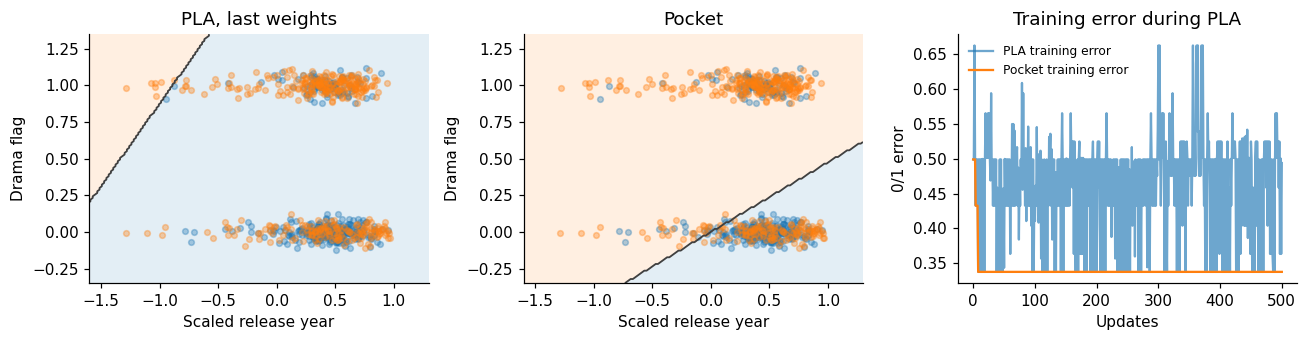

,model,train error,validation error
0,PLA last,0.494,0.498
1,Pocket,0.338,0.346


In [6]:
#@title PLA and Pocket on year and Drama (run as is)
pla2=None
if pla_ready:
    pla2=fit_pla_pocket(X_train[:,:2],y_train)
    fig,axes=plt.subplots(1,3,figsize=(12,3.2))
    line_map(axes[0],X_train[:700,:2],y_train[:700],pla2['last'],'PLA, last weights')
    line_map(axes[1],X_train[:700,:2],y_train[:700],pla2['pocket'],'Pocket')
    for ax in axes[:2]:ax.set(xlabel='Scaled release year',ylabel='Drama flag')
    h=pla2['history']
    axes[2].plot(h[:,0],h[:,1],alpha=.65,label='PLA training error')
    axes[2].plot(h[:,0],h[:,2],color=ORANGE,label='Pocket training error')
    axes[2].set(xlabel='Updates',ylabel='0/1 error',title='Training error during PLA')
    axes[2].legend(frameon=False,fontsize=8)
    plt.tight_layout();plt.show()
    rows=[]
    for name,w in [('PLA last',pla2['last']),('Pocket',pla2['pocket'])]:
        rows.append({'model':name,'train error':np.mean(predict(X_train[:,:2],w)!=y_train),
                     'validation error':np.mean(predict(X_val[:,:2],w)!=y_val)})
    display(pd.DataFrame(rows).round(3))
else:
    note('Complete Task 3 first.')

Why can the last PLA weights be worse than weights found earlier? Does a lower training error guarantee a lower validation error? One or two sentences.

**Answer:** The last PLA weights can be worse because an update made to correct one misclassified example can cause previously correct examples to become incorrect. A lower training error does not guarantee a lower validation error because the model may fit the training data better without generalizing better to unseen data.


(Many movies have the same year and genre, so the plots add a small random jitter to the points. The model uses the original values.)


## Part 3: Linear regression and nonlinear features

Lecture 3. Tasks 4–5.


### Task 4: Linear regression

Complete `fit_ls` so that it returns the least-squares weights $w = X^{\dagger}y$, using `np.linalg.pinv` and a matrix–vector product. We use the pseudo-inverse because in Task 5 some feature columns are linearly dependent, and then $(X^\top X)^{-1}$ does not exist.

The same function is used twice: fitted to `score_train` it is a regression model, and fitted to the ±1 labels and followed by sign it is a classifier, as in Lecture 3. The two have separate weights. Predicted scores are clipped to [1, 10].

What is the difference between a predicted score of 7.4 and a predicted label of +1? One sentence.

**Answer:** A predicted score of 7.4 is a numerical regression estimate of the movie's rating, whereas a predicted label of +1 is a classification decision indicating that the predicted class is at least 7.

In [7]:
def fit_ls(X, y):
    Xb = bias(X)
    w = np.linalg.pinv(Xb) @ y  # TODO T4: pseudoinverse of Xb multiplied by y
    return w

fit_probe = fit_ls(np.array([[0.],[1.],[2.]]), np.array([1.,3.,5.]))
ls_ready = fit_probe is not None
if ls_ready:
    assert np.allclose(fit_probe, [1.,2.]), 'This small regression has intercept 1 and slope 2.'
    note('Task 4: all checks passed.')
else:
    note('Fill in T4 and run the cell again.')

Task 4: all checks passed.


### Task 5: Nonlinear transform

Complete $\Phi(X)$. It returns the original columns, their squares, and the product of the first two columns.

- T5a: the element-wise squares of `X`, shape `(N, d)`.
- T5b: column 0 times column 1, shape `(N,)`.

On the movie data the product is year × Drama, which lets the effect of the year be different for dramas. The square of a 0/1 genre flag equals the flag itself, which is one reason `fit_ls` needs the pseudo-inverse. Don't add a bias column; `fit_ls` does that.

The next cell first applies $\Phi$ to a synthetic dataset with a circular class boundary, then to the movies.

Is the transformed model still linear in $w$? Is its decision boundary a straight line in the original inputs? Two short answers.

**Answer:** Yes, The model remains linear in its weights because the transformed features are multiplied by weights and then added together.
No. Although the model is linear in the transformed feature space, its decision boundary can be nonlinear in the original input space.

In [8]:
def phi(X):
    squares = X ** 2  # TODO T5a: element-wise squares of X
    interaction = X[:, 0] * X[:, 1]  # TODO T5b: product of the first two columns
    if squares is None or interaction is None:
        return None
    return np.column_stack([X, squares, interaction])

p = phi(np.array([[2.,3.],[-1.,4.]]))
phi_ready = p is not None
if phi_ready:
    assert p.shape == (2,5), 'Expected original columns, squares, then one interaction.'
    assert np.allclose(p, [[2,3,4,9,6],[-1,4,1,16,-4]])
    note('Task 5: all checks passed.')
else:
    note('Fill in T5a–T5b and run the cell again.')

Task 5: all checks passed.


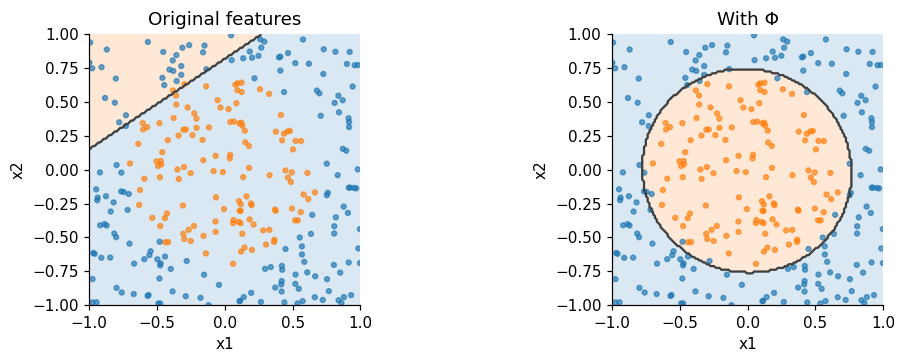

,train 0/1,validation 0/1,validation cost,validation RMSE
model,,,,
Train majority / mean,0.499,0.500,2.000,1.017
Never recommend,0.501,0.500,0.500,NaN
Linear LS,0.350,0.346,0.769,0.931
Nonlinear LS,0.327,0.348,0.804,0.910
Pocket,0.325,0.333,0.861,NaN


Lower is better in every column. Pocket and Never recommend only output labels, so they have no RMSE.


In [9]:
#@title Circle example and model comparison (run as is)
candidates,reg_candidates={},{}

def rating_prediction(X,w):
    return np.clip(bias(X) @ w,1,10)

if ls_ready and phi_ready:
    r=np.random.default_rng(21)
    toy_X=r.uniform(-1,1,(300,2))
    toy_y=np.where(np.sum(toy_X**2,axis=1)<.5,1,-1)
    gx,gy=np.meshgrid(np.linspace(-1,1,150),np.linspace(-1,1,150))
    grid=np.column_stack([gx.ravel(),gy.ravel()])
    fig,axes=plt.subplots(1,2,figsize=(10,3.4))
    for ax,(name,transform) in zip(axes,[('Original features',lambda x:x),('With Φ',phi)]):
        w=fit_ls(transform(toy_X),toy_y)
        zz=predict(transform(grid),w).reshape(gx.shape)
        ax.contourf(gx,gy,zz,levels=[-2,0,2],colors=[BLUE,ORANGE],alpha=.17)
        if zz.min()!=zz.max():ax.contour(gx,gy,zz,levels=[0],colors=[DARK])
        ax.scatter(*toy_X.T,c=np.where(toy_y==1,ORANGE,BLUE),s=10,alpha=.65)
        ax.set(title=name,xlabel='x1',ylabel='x2');ax.set_aspect('equal')
    plt.tight_layout();plt.show()
    for name,transform in [('Linear LS',lambda x:x),('Nonlinear LS',phi)]:
        candidates[name]=(transform,fit_ls(transform(X_train),y_train))
        reg_candidates[name]=(transform,fit_ls(transform(X_train),score_train))
if pla_ready:
    result6=fit_pla_pocket(X_train,y_train,steps=600)
    candidates['Pocket']=(lambda x:x,result6['pocket'])
if candidates and losses_ready:
    majority=1 if np.mean(y_train==1)>=.5 else -1
    rows=[{'model':'Train majority / mean','train 0/1':binary_error(y_train,np.full(len(y_train),majority)),
           'validation 0/1':binary_error(y_val,np.full(len(y_val),majority)),
           'validation cost':watch_cost(y_val,np.full(len(y_val),majority)),
           'validation RMSE':np.sqrt(squared_error(score_val,np.full(len(score_val),score_train.mean())))},
          {'model':'Never recommend','train 0/1':binary_error(y_train,np.full(len(y_train),-1)),
           'validation 0/1':binary_error(y_val,np.full(len(y_val),-1)),
           'validation cost':watch_cost(y_val,np.full(len(y_val),-1)),
           'validation RMSE':np.nan}]
    for name,(transform,w) in candidates.items():
        row={'model':name,'train 0/1':binary_error(y_train,predict(transform(X_train),w)),
             'validation 0/1':binary_error(y_val,predict(transform(X_val),w)),
             'validation cost':watch_cost(y_val,predict(transform(X_val),w)),
             'validation RMSE':np.nan}
        if name in reg_candidates:
            rt,rw=reg_candidates[name]
            row['validation RMSE']=np.sqrt(squared_error(score_val,rating_prediction(rt(X_val),rw)))
        rows.append(row)
    validation_report=pd.DataFrame(rows).set_index('model')
    display(validation_report.round(3))
    note('Lower is better in every column. Pocket and Never recommend only output labels, so they have no RMSE.')
else:
    note('Complete Tasks 2–5 first.')

In the table, "Never recommend" has a lower validation cost than all three trained classifiers. How is that possible with our 4:1 costs? If you knew $P(y=+1\mid x)$ exactly, above what probability should a movie be recommended? Two sentences.

**Answer:** "Never recommend" can achieve a lower cost because the penalty for a false positive is four times the penalty for a false negative, making a conservative classifier potentially preferable when positive examples are relatively uncommon. If $p=P(y=+1\mid x)$, we should recommend when $4(1-p)<p$, which gives $p>0.8$.

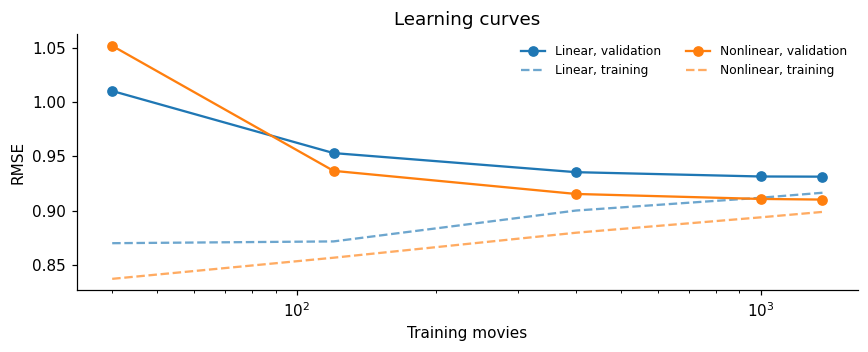

In [10]:
#@title Learning curves (run as is)
if ls_ready and phi_ready and losses_ready:
    sizes=[40,120,400,min(1000,len(y_train)),len(y_train)]
    fig,ax=plt.subplots(figsize=(8,3.3))
    for name,transform in [('Linear',lambda x:x),('Nonlinear',phi)]:
        train_errors,val_errors=[],[]
        for n in sizes:
            pairs=[]
            for repeat in range(10):
                ids=np.random.default_rng(50+repeat).permutation(len(y_train))[:n]
                w=fit_ls(transform(X_train[ids]),score_train[ids])
                pairs.append([np.sqrt(squared_error(score_train[ids],rating_prediction(transform(X_train[ids]),w))),
                              np.sqrt(squared_error(score_val,rating_prediction(transform(X_val),w)))])
            train_errors.append(np.mean(pairs,axis=0)[0]);val_errors.append(np.mean(pairs,axis=0)[1])
        line,=ax.plot(sizes,val_errors,'o-',label=name+', validation')
        ax.plot(sizes,train_errors,'--',color=line.get_color(),alpha=.65,label=name+', training')
    ax.set(xscale='log',xlabel='Training movies',ylabel='RMSE',
           title='Learning curves')
    ax.legend(frameon=False,fontsize=8,ncol=2)
    plt.tight_layout();plt.show()
else:
    note('Complete Tasks 2, 4 and 5 first.')

Compare the training and validation RMSE at the smallest training size. Do the extra features always help on the validation set? Two sentences.

**Answer:** At the smallest training size, the training RMSE is generally lower than the validation RMSE because the model is fitted directly to the training samples. Extra features do not always improve validation performance, since they can increase model complexity and cause overfitting when training data is limited.


Each point is an average over ten random training subsets. We keep looking at the validation set while exploring, so the best validation score we see is slightly optimistic. The test set is used only once, at the end.


## Part 4: Noise

Lecture 4. Task 6.


### Task 6: Noisy targets

Let $y=f(x)+\xi$, where given $x$ the noise $\xi$ has mean 0 and variance $\sigma^2$. If a fixed hypothesis $g$ has mean squared error $q$ with respect to $f$, its expected squared error on new noisy examples is

$$E_{\text{noisy}} = q + \sigma^2.$$

Return this in `noisy_mse(q, sigma)`. Note that even $g=f$ has error $\sigma^2$. The cell then checks the formula on a synthetic regression problem with three noise levels.

What is the difference between $P(x)$ and $P(y\mid x)$? Which of the two changes in this experiment when $\sigma$ grows? Two sentences.

**Answer:** $P(x)$ describes the distribution of input features, whereas $P(y\mid x)$ describes the distribution of target values given those inputs. In this experiment, increasing $\sigma$ changes $P(y\mid x)$ by increasing the target noise variance, while $P(x)$ remains unchanged.

In [11]:
def noisy_mse(q,sigma):
    value = q + sigma ** 2  # TODO T6: clean-model MSE plus noise variance
    return value

noise_ready=noisy_mse(20,3) is not None
if noise_ready:
    assert np.isclose(noisy_mse(20,3),29)
    assert np.isclose(noisy_mse(0,5),25)
    note('Task 6: all checks passed.')
    if ls_ready and phi_ready and losses_ready:
        rr=np.random.default_rng(4)
        nx=rr.uniform(0,1,(600,2));ex=rr.uniform(0,1,(12000,2))
        def clean_signal(x):return 4+1.2*x[:,0]**2+.8*x[:,1]
        clean_train,clean_eval=clean_signal(nx),clean_signal(ex)
        rows=[]
        for sigma in [0,.3,.7]:
            noisy_train=clean_train+rr.normal(0,sigma,len(nx))
            noisy_eval=clean_eval+rr.normal(0,sigma,len(ex))
            w=fit_ls(phi(nx),noisy_train)
            tr_pred=bias(phi(nx)) @ w;ev_pred=bias(phi(ex)) @ w
            clean_q=squared_error(clean_eval,ev_pred)
            rows.append({'noise SD':sigma,'training noisy MSE':squared_error(noisy_train,tr_pred),
                         'fresh noisy MSE':squared_error(noisy_eval,ev_pred),
                         'expected from clean q':noisy_mse(clean_q,sigma)})
        display(pd.DataFrame(rows).round(2))
else:
    note('Fill in T6 and run the cell again.')

Task 6: all checks passed.


,noise SD,training noisy MSE,fresh noisy MSE,expected from clean q
0,0.0,0.00,0.00,0.00
1,0.3,0.09,0.09,0.09
2,0.7,0.47,0.50,0.50


## Part 5: Hoeffding's inequality and many hypotheses

Lecture 2. Task 7.


### Task 7: Hoeffding's inequality

For a single hypothesis $h$ fixed before the data is drawn, and $N$ i.i.d. examples,

$$\Pr\big[|E_{in}(h)-E_{out}(h)|>\epsilon\big]\le \;?$$

Write the right-hand side from Lecture 2 in `hoeffding(N, eps)`, using `np.exp`. The plot caps the bound at 1.

The simulation draws Bernoulli errors with true error rate $\mu=0.2$ and compares the observed frequency of $|\nu-\mu|>0.1$ with the bound.


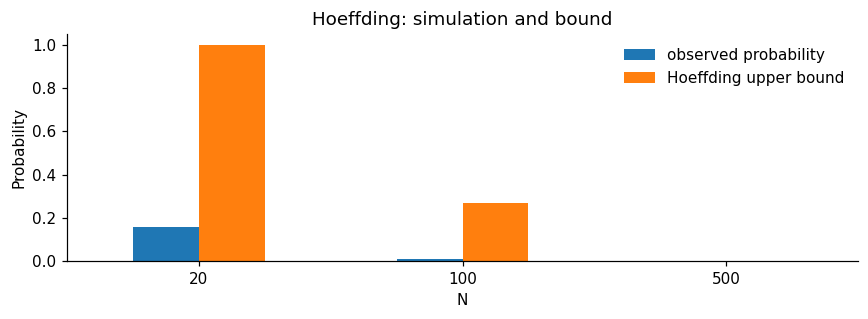

Task 7: all checks passed.


In [12]:
def hoeffding(N, eps):
    bound = 2 * np.exp(-2 * N * eps ** 2)  # TODO T7: two-sided Hoeffding bound for one fixed hypothesis
    return bound

hoeffding_ready = hoeffding(100,.1) is not None
if hoeffding_ready:
    assert np.isclose(hoeffding(100,.1),.2706705664732254)
    assert hoeffding(300,.1) < hoeffding(100,.1), 'More data should tighten this bound.'
    rr = np.random.default_rng(5); mu, eps, trials = .2,.1,20000
    sample_rows=[]
    for N in [20,100,500]:
        nu = rr.binomial(N,mu,size=trials)/N
        sample_rows.append({'N':N,'observed probability':np.mean(np.abs(nu-mu)>eps+1e-12),
                            'Hoeffding upper bound':min(1.,hoeffding(N,eps))})
    view = pd.DataFrame(sample_rows)
    ax = view.set_index('N').plot.bar(color=[BLUE,ORANGE],rot=0,figsize=(8,3))
    ax.set(ylabel='Probability',title='Hoeffding: simulation and bound')
    ax.legend(frameon=False); plt.tight_layout(); plt.show()
    note('Task 7: all checks passed.')
else:
    note('Fill in T7 and run the cell again.')

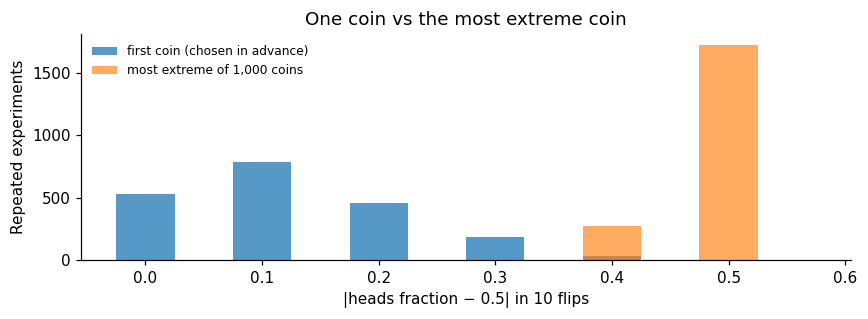

In [13]:
#@title 1,000 fair coins (run as is)
rr = np.random.default_rng(19)
heads = rr.binomial(10,.5,size=(2000,1000))/10
fixed_gap = np.abs(heads[:,0]-.5)
chosen_gap = np.max(np.abs(heads-.5),axis=1)
fig,ax=plt.subplots(figsize=(8,3))
ax.hist(fixed_gap,bins=np.arange(-.025,.576,.05),alpha=.75,color=BLUE,label='first coin (chosen in advance)')
ax.hist(chosen_gap,bins=np.arange(-.025,.576,.05),alpha=.65,color=ORANGE,label='most extreme of 1,000 coins')
ax.set(xlabel='|heads fraction − 0.5| in 10 flips',ylabel='Repeated experiments',title='One coin vs the most extreme coin')
ax.legend(frameon=False,fontsize=8); plt.tight_layout(); plt.show()

All 1,000 coins are fair. Why does the most extreme one look biased, and what is the corresponding mistake when we try many models on the same data? Two sentences.

**Answer:** Although all coins are fair, examining 1,000 coins makes it likely that at least one will produce an unusually extreme result purely by chance. Similarly, trying many models on the same dataset and selecting the one with the lowest training error can lead to overfitting because the selected model may have benefited from random fluctuations in that particular dataset.


For $M$ hypotheses fixed in advance, the union bound gives $\Pr[|E_{in}(g)-E_{out}(g)|>\epsilon]\le 2Me^{-2N\epsilon^2}$. For the perceptron $M$ is infinite, which is why Part 6 replaces $M$ with the growth function.


## Part 6: Growth function and the VC bound

Lectures 5 and 6. Tasks 8–9.


### Task 8: Break points and $B(N,k)$

A dichotomy is one ±1 labelling of $N$ points that $\mathcal H$ can produce. The growth function $m_{\mathcal H}(N)$ is the largest number of dichotomies over all choices of $N$ points. $k$ is a break point if $m_{\mathcal H}(k)<2^k$, and the smallest break point is $d_{VC}+1$.

| $\mathcal H$ | $m_{\mathcal H}(N)$ | smallest break point | $d_{VC}$ |
|:--|:--|:--|:--|
| positive rays | $N+1$ | 2 | 1 |
| positive intervals | $\tfrac12 N(N+1)+1$ | 3 | 2 |
| perceptron in $\mathbb R^2$ | 8 for $N=3$, 14 for $N=4$ | 4 | 3 |
| convex sets | $2^N$ | none | $\infty$ |

The cell below checks the perceptron row: for three and for four points in the plane, it tries every labelling and solves a small linear program to see whether a separating line exists.

If $\mathcal H$ has a break point $k$, then $m_{\mathcal H}(N)\le B(N,k)$ (Lecture 6).

- T8a: return the recursion $B(N-1,k)+B(N-1,k-1)$.
- T8b: in `growth_upper`, return $\sum_{i=0}^{k-1}\binom{N}{i}$ using `math.comb`. Stop the sum at $\min(k-1,N)$.


Task 8: all checks passed.


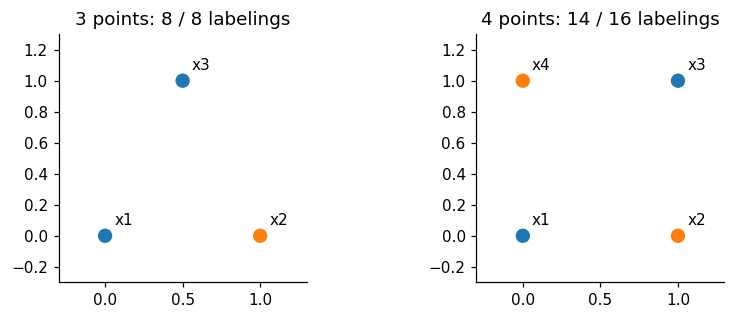

In [14]:
# Feasibility helper: no student changes needed here.
def can_separate(points, labels):
    signed_rows = labels[:,None] * bias(points)
    result = linprog(np.zeros(points.shape[1]+1), A_ub=-signed_rows,
                     b_ub=-np.ones(len(points)),
                     bounds=[(None,None)]*(points.shape[1]+1), method='highs')
    return result.success

def B(N,k):
    if N == 0 or k == 1:
        return 1
    if k > N:
        return 2**N
    value = B(N-1, k) + B(N-1, k-1)  # TODO T8a: the two-term recursive bound
    return value

def growth_upper(N,k):
    value = sum(math.comb(N, i) for i in range(min(k-1, N) + 1))  # TODO T8b: sum of binomial coefficients
    return value

growth_ready = B(3,3) is not None and growth_upper(3,3) is not None
if growth_ready:
    for N in range(1,8):
        for k in range(1,10):
            assert B(N,k) == growth_upper(N,k), 'The recursion and binomial sum should agree.'
    assert growth_upper(5,3) == 16
    note('Task 8: all checks passed.')
else:
    note('Fill in T8a–T8b and run the cell again. The plot below works without them.')

geometry = [np.array([[0,0],[1,0],[.5,1]]), np.array([[0,0],[1,0],[1,1],[0,1]])]
fig, axes = plt.subplots(1,2,figsize=(8,3))
for ax, points in zip(axes,geometry):
    labelings = list(itertools.product([-1,1],repeat=len(points)))
    possible = [can_separate(points,np.array(labels)) for labels in labelings]
    colors = [BLUE,ORANGE,BLUE,ORANGE][:len(points)]
    ax.scatter(*points.T,c=colors,s=130,edgecolors='white',linewidths=2)
    for i,(x,y) in enumerate(points): ax.annotate(f'x{i+1}',(x,y),xytext=(6,7),textcoords='offset points')
    ax.set(title=f'{len(points)} points: {sum(possible)} / {2**len(points)} labelings',
           xlim=(-.3,1.3),ylim=(-.3,1.3)); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

Which two labellings of the square's corners can't be separated by a line? Why doesn't one set of 4 points that can't be shattered prove that 4 is a break point? Two sentences.

**Answer:** The two alternating labelings, where diagonally opposite corners share the same label, cannot be separated by a straight line. However, one arrangement of four points that cannot be shattered does not prove that four is a break point, because the definition requires showing that no arrangement of four points can be shattered.

### Task 9: The VC bound for our classifiers

The VC inequality from Lecture 6 is

$$\Pr\big[|E_{in}(g)-E_{out}(g)|>\epsilon\big]\le 4\,m_{\mathcal H}(2N)\,e^{-N\epsilon^2/8}.$$

Setting the right-hand side equal to $\delta$ and solving for $\epsilon$ gives, with probability at least $1-\delta$,

$$E_{out}(g)\le E_{in}(g)+\sqrt{\frac{8}{N}\ln\frac{4\,m_{\mathcal H}(2N)}{\delta}}.$$

We now apply this to the classifiers from Part 3. Linear LS and Pocket are perceptrons on the $d=6$ movie inputs, so $d_{VC}=d+1=7$ and the break point is $k=8$. Nonlinear LS is a perceptron on the 13 columns of $\Phi(x)$, so $d_{VC}\le 14$ and $k=15$ is a break point. In both cases $m_{\mathcal H}(2N)$ is replaced by its upper bound `growth_upper(2*N, k)`.

- T9a: `vc_probability(N, eps, k)` returns the right-hand side of the VC inequality.
- T9b: `vc_penalty(N, delta, k)` returns the square-root term.

The table then compares the VC bound with the bound we get from the validation set. Since we compare three classifiers on it, Hoeffding with the union bound for $M=3$ gives $E_{out}\le E_{val}+\sqrt{\ln(2M/\delta)/(2N_{val})}$. Both bounds treat the movies as independent samples, which is only approximately true here.


Task 9: all checks passed.


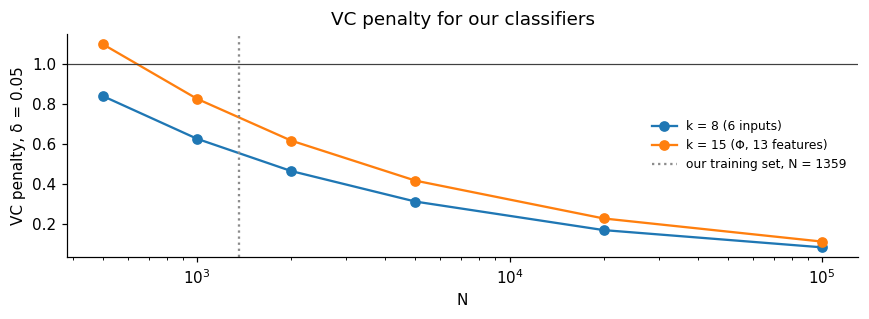

,k,E_in,VC penalty,VC bound on E_out,E_val,validation bound on E_out
classifier,,,,,,
Linear LS,8,0.350,0.549,0.899,0.346,0.418
Pocket,8,0.325,0.549,0.874,0.333,0.405
Nonlinear LS,15,0.327,0.727,1.055,0.348,0.421


In [15]:
D = X_train.shape[1]            # 6 movie inputs
K_LINEAR = D + 2                # perceptron on 6 inputs: d_VC = 7, break point 8
K_NONLINEAR = (2*D + 1) + 2     # perceptron on the 13 columns of Phi: d_VC <= 14, break point 15

def vc_probability(N, eps, k=K_LINEAR):
    if growth_upper(2*N, k) is None:
        return None
    value = 4 * growth_upper(2*N, k) * np.exp(-N * eps ** 2 / 8)  # TODO T9a: right-hand side of the VC inequality, using growth_upper(2*N, k)
    return value

def vc_penalty(N, delta=.05, k=K_LINEAR):
    if growth_upper(2*N, k) is None:
        return None
    value = np.sqrt((8/N) * np.log(4 * growth_upper(2*N, k) / delta))  # TODO T9b: the square-root penalty
    return value

vc_ready = growth_ready and vc_probability(100, .1) is not None and vc_penalty(100) is not None
if vc_ready:
    assert vc_penalty(10000) < vc_penalty(1000)
    assert vc_penalty(1000, delta=.01) > vc_penalty(1000, delta=.1)
    assert vc_penalty(1000, k=K_NONLINEAR) > vc_penalty(1000, k=K_LINEAR)
    assert np.isclose(vc_probability(1000, vc_penalty(1000)), .05)
    note('Task 9: all checks passed.')

    N_train, N_val, delta = len(y_train), len(y_val), .05
    ns = np.array([500, 1000, 2000, 5000, 20000, 100000])
    fig, ax = plt.subplots(figsize=(8, 3))
    for k, label in [(K_LINEAR, f'k = {K_LINEAR} (6 inputs)'), (K_NONLINEAR, f'k = {K_NONLINEAR} (Φ, 13 features)')]:
        ax.plot(ns, [vc_penalty(int(n), delta, k) for n in ns], 'o-', label=label)
    ax.axvline(N_train, color=GREY, ls=':', label=f'our training set, N = {N_train}')
    ax.axhline(1, color=DARK, lw=.8)
    ax.set(xscale='log', xlabel='N', ylabel='VC penalty, δ = 0.05', title='VC penalty for our classifiers')
    ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

    models = globals().get('candidates', {})
    if models:
        eps_val = np.sqrt(np.log(2*3/delta) / (2*N_val))   # Hoeffding + union bound, M = 3
        rows = []
        for name, k in [('Linear LS', K_LINEAR), ('Pocket', K_LINEAR), ('Nonlinear LS', K_NONLINEAR)]:
            if name not in models:
                continue
            t, w = models[name]
            e_in = binary_error(y_train, predict(t(X_train), w))
            e_val = binary_error(y_val, predict(t(X_val), w))
            pen = vc_penalty(N_train, delta, k)
            rows.append({'classifier': name, 'k': k, 'E_in': e_in, 'VC penalty': pen,
                         'VC bound on E_out': e_in + pen, 'E_val': e_val,
                         'validation bound on E_out': e_val + eps_val})
        display(pd.DataFrame(rows).set_index('classifier').round(3))
    else:
        note('Run the model comparison cell in Part 3 to see the table.')
else:
    note('Fill in T9a–T9b and run the cell again.')


Which bound on $E_{out}$ is tighter, the VC bound or the validation bound, and why? Why is the VC penalty of Nonlinear LS larger than that of Linear LS? Two sentences.

**Answer:** The validation bound is tighter for all three classifiers because it uses a separate validation set and gives smaller upper bounds than the VC bound in our experiment. The VC penalty of Nonlinear LS is larger because its transformed feature space has 13 features instead of 6, resulting in a larger VC dimension upper bound and growth-function bound.

## Final part: the test set and the poster movies

### Task 10: Choose a model

Choose `'Linear LS'` or `'Nonlinear LS'` from the validation results, mainly by RMSE and then by watch cost. Each choice includes a regression model (for scores) and a classifier (for labels). Set `chosen_name` before running the cell. The cell evaluates the chosen model once on the test set and then shows the scores of the poster movies. Nothing is retrained.

**Answer:** I chose Nonlinear LS because it achieved a lower validation RMSE (0.910) than Linear LS (0.931), indicating better numerical rating predictions. Although its validation watch cost (0.804) was slightly higher than Linear LS (0.769), I prioritized RMSE as instructed.


,frozen model,test movies,test RMSE,train-mean baseline RMSE,test 0/1 error,test watch cost,never-recommend cost
0,Nonlinear LS,454,0.971,1.042,0.346,0.828,0.5


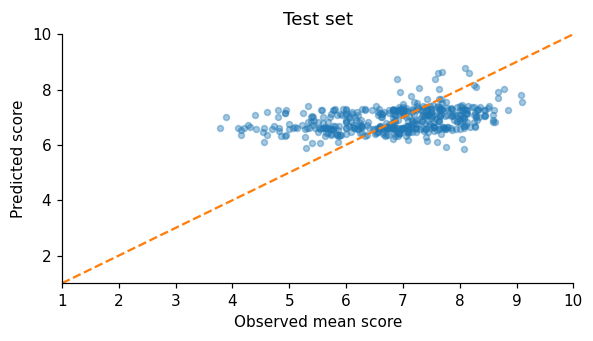

Poster movies:


,film,your guess,model guess,MovieLens mean /10,ratings in this sample,seen before
0,"Avengers, The (1998)",6.8,6.56,4.64,11,False
1,"Wicker Man, The (2006)",7.5,6.36,2.00,4,False
2,Jack and Jill (2011),5.4,6.71,4.60,5,False
3,Batman & Robin (1997),7.3,6.56,4.43,42,False


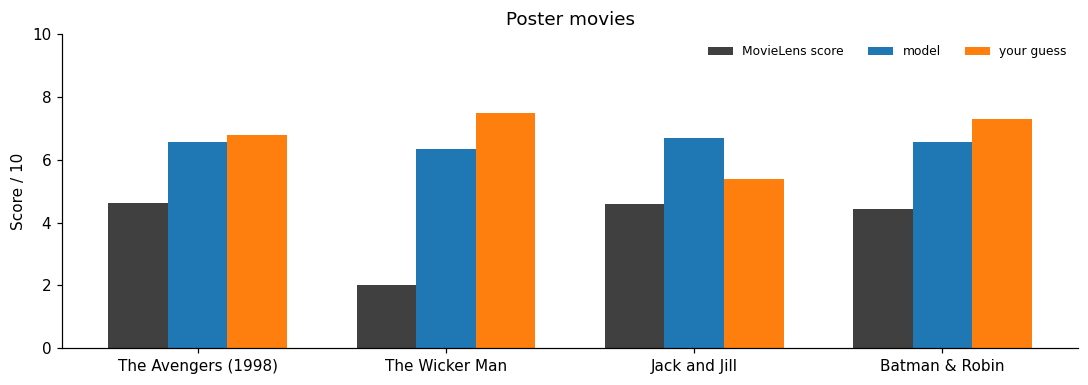

,,RMSE
0,your guesses,3.310
1,model,2.814


RMSE over the 4 movies you had not seen.


In [16]:
chosen_name = 'Nonlinear LS'  # TODO T10: 'Linear LS' or 'Nonlinear LS', chosen on validation

if chosen_name is None:
    note('Set chosen_name first.')
elif not all(globals().get(flag,False) for flag in ['losses_ready','pla_ready','ls_ready','phi_ready','noise_ready','hoeffding_ready','growth_ready','vc_ready']):
    note('Complete Tasks 2–9 first.')
elif chosen_name not in globals().get('reg_candidates',{}):
    note("Run the model comparison cell first, then choose 'Linear LS' or 'Nonlinear LS'.")
elif globals().get('test_opened',False):
    note('The test set has already been used. Showing the earlier result.')
    display(final_report)
else:
    ct,cw=candidates[chosen_name];rt,rw=reg_candidates[chosen_name]
    xt,yt,actual=locked_test['X'],locked_test['y'],locked_test['score']
    pred_labels=predict(ct(xt),cw)
    predicted=rating_prediction(rt(xt),rw)
    final_report=pd.DataFrame([{
        'frozen model':chosen_name,'test movies':len(yt),
        'test RMSE':np.sqrt(squared_error(actual,predicted)),
        'train-mean baseline RMSE':np.sqrt(squared_error(actual,np.full(len(actual),score_train.mean()))),
        'test 0/1 error':binary_error(yt,pred_labels),
        'test watch cost':watch_cost(yt,pred_labels),
        'never-recommend cost':watch_cost(yt,np.full(len(yt),-1))}])
    test_opened=True;challenge_revealed=True
    display(final_report.round(3))
    fig,ax=plt.subplots(figsize=(5.5,3.2))
    ax.scatter(actual,predicted,s=15,color=BLUE,alpha=.4)
    ax.plot([1,10],[1,10],'--',color=ORANGE)
    ax.set(xlabel='Observed mean score',ylabel='Predicted score',title='Test set',
           xlim=(1,10),ylim=(1,10))
    plt.tight_layout();plt.show()

    # Poster movies (not part of the random test set).
    chx=prepare_features(challenge)
    ch_actual=challenge['score10'].to_numpy()
    ch_model=rating_prediction(rt(chx),rw)
    guesses=globals().get('human_guesses',[None]*4)
    seen=np.array(globals().get('seen_before',[False]*4),dtype=bool)
    guess_array=np.array([np.nan if g is None else float(g) for g in guesses])
    valid=np.isfinite(guess_array)&~seen
    reveal=pd.DataFrame({
        'film':challenge['title'], 'your guess':guess_array,
        'model guess':ch_model,'MovieLens mean /10':ch_actual,
        'ratings in this sample':challenge['count'],
        'seen before':seen})
    note('Poster movies:')
    display(reveal.round(2))
    labels=['The Avengers (1998)','The Wicker Man','Jack and Jill','Batman & Robin']
    x=np.arange(4);width=.24
    fig,ax=plt.subplots(figsize=(10,3.6))
    ax.bar(x-width,ch_actual,width,label='MovieLens score',color=DARK)
    ax.bar(x,ch_model,width,label='model',color=BLUE)
    if np.any(np.isfinite(guess_array)):
        ax.bar(x+width,guess_array,width,label='your guess',color=ORANGE)
    ax.set(xticks=x,xticklabels=labels,ylabel='Score / 10',ylim=(0,10),title='Poster movies')
    ax.legend(frameon=False,fontsize=8,ncol=3);plt.tight_layout();plt.show()
    if valid.any():
        human_rmse=np.sqrt(squared_error(ch_actual[valid],guess_array[valid]))
        model_rmse=np.sqrt(squared_error(ch_actual[valid],ch_model[valid]))
        display(pd.DataFrame({'':['your guesses','model'],
                              'RMSE':[human_rmse,model_rmse]}).round(3))
        note(f'RMSE over the {valid.sum()} movies you had not seen.')
    else:
        note('No guesses were recorded.')


### Final questions

1. Did your model beat the baselines on the test set? Compare its RMSE with the train-mean baseline, and its watch cost with "never recommend". One or two sentences.

   **Answer:** The model outperformed the train-mean baseline in terms of RMSE (0.971 vs. 1.042), meaning it made more accurate numerical rating predictions. However, its watch cost (0.828) was higher than that of the never-recommend baseline (0.500), so it did not outperform both baselines.

2. Did an actor or a poster influence your guesses? Why can't four hand-picked movies tell us whether famous actors make better films? One or two sentences.

   **Answer:** My guesses were influenced mainly by actors (such as Nicolas Cage) and genres (like Batman & Robin) which shaped my initial expectations about the films. However, four hand-picked movies are too small and potentially biased a sample to establish whether famous actors make better films, especially since factors such as genre, directing, and storytelling are not controlled.

3. Two of the poster movies have only 4 and 5 ratings, another has 42. Are their mean scores equally reliable? One sentence.

   **Answer:** No. A movie with 42 ratings generally has a more reliable mean score than movies with only 4 or 5 ratings, because a larger sample size reduces the variability of the estimated average.

### Sources

- Data: F. M. Harper and J. A. Konstan, "The MovieLens Datasets: History and Context," *ACM TiiS* 5(4), 2015, [doi:10.1145/2827872](https://doi.org/10.1145/2827872). [MovieLens latest-small](https://grouplens.org/datasets/movielens/latest/), GroupLens Research, University of Minnesota. The table in this notebook (per-movie mean and count, filtered by year and number of ratings) is redistributed under the original [usage conditions](https://files.grouplens.org/datasets/movielens/ml-latest-small-README.html), which are also stored in the notebook metadata: research and non-commercial use, with attribution and no implied endorsement.
- Posters and cast: [The Avengers (1998)](https://www.imdb.com/title/tt0118661/), [The Wicker Man (2006)](https://www.impawards.com/2006/wicker_man_ver3_xlg.html), [Jack and Jill (2011)](https://nitehawkcinema.com/prospectpark/movies/jack-and-jill/), [Batman & Robin (1997)](https://www.originalfilmart.com/products/batman-and-robin-97). The posters belong to their rights holders and are shown at low resolution for teaching.
- Theory: Y. S. Abu-Mostafa, *Learning From Data*, Lectures 1–6, Caltech, 2012. Slides: [1](https://dl.inl-lab.net/files/Courses/24-09-ML/Slides/ML-Lec01_2.pdf), [2](https://dl.inl-lab.net/files/Courses/24-09-ML/Slides/ML-Lec02.pdf), [3](https://dl.inl-lab.net/files/Courses/24-09-ML/Slides/ML-Lec03.pdf), [4](https://dl.inl-lab.net/files/Courses/24-09-ML/Slides/ML-Lec04.pdf), [5](https://dl.inl-lab.net/files/Courses/24-09-ML/Slides/ML-Lec05.pdf), [6](https://dl.inl-lab.net/files/Courses/24-09-ML/Slides/ML-Lec06.pdf).
